<a href="https://colab.research.google.com/github/GOWTHAMVANTAKULA/Financial-Forecasting-Frontier-Distributed-ML/blob/main/Exploratory_Data_Analysis_(EDA)_with_Spark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Exploratory_Data_Analysis_(EDA)_with_Spark**

**1.	Data Loading and Basic Inspection:**

* Load the bank.csv dataset into a Spark DataFrame.

*	Perform basic data inspection tasks such as showing the first few rows, printing the schema, and displaying a summary of numerical columns.


In [1]:
# Step 1: Setup PySpark in Google Colab

# Install PySpark
!pip install -q pyspark==3.5.1

# Import SparkSession
from pyspark.sql import SparkSession

# Create Spark Session
spark = SparkSession.builder \
    .master("local[*]") \
    .appName("BankMarketingAnalysis") \
    .getOrCreate()

print("✅ Spark Session Created Successfully")
print("Spark Version:", spark.version)



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 317.0/317.0 MB 4.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 200.5/200.5 kB 13.4 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.1 which is incompatible.
✅ Spark Session Created Successfully
Spark Version: 3.5.1


In [3]:
# Load bank.csv
file_path = "/content/drive/MyDrive/Financial Forecasting Frontier: Distributed ML/bank.csv"

df = spark.read.csv(
    file_path,
    header=True,
    inferSchema=True
)

# Display the first 5 rows
print("First 5 Rows:")
df.show(5, truncate=False)

# Display the dataset schema
print("Dataset Schema:")
df.printSchema()

# Display summary of numerical columns
print("Summary of Numerical Columns:")
df.describe(
    "age",
    "balance",
    "day",
    "duration",
    "campaign",
    "pdays",
    "previous"
).show()

# Display total number of records and columns
print("Total Rows:", df.count())
print("Total Columns:", len(df.columns))


First 5 Rows:
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|age|job        |marital|education|default|balance|housing|loan|contact |day|month|duration|campaign|pdays|previous|poutcome|y  |
+---+-----------+-------+---------+-------+-------+-------+----+--------+---+-----+--------+--------+-----+--------+--------+---+
|30 |unemployed |married|primary  |no     |1787   |no     |no  |cellular|19 |oct  |79      |1       |-1   |0       |unknown |no |
|33 |services   |married|secondary|no     |4789   |yes    |yes |cellular|11 |may  |220     |1       |339  |4       |failure |no |
|35 |management |single |tertiary |no     |1350   |yes    |no  |cellular|16 |apr  |185     |1       |330  |1       |failure |no |
|30 |management |married|tertiary |no     |1476   |yes    |yes |unknown |3  |jun  |199     |4       |-1   |0       |unknown |no |
|59 |blue-collar|married|secondary|no     |0      |yes    |no  |unknown |5  

**2.	Data Filtering and Column Operations:**



* Filter the dataset to include only clients with a balance greater than a certain threshold (e.g., 1000).

In [5]:
filtered_df = df.filter(df["balance"] > 1000)

print("Clients with Balance Greater Than 1000:")
filtered_df.show(10, truncate=False)

print("Total Number of Clients:", filtered_df.count())


Clients with Balance Greater Than 1000:
+---+----------+--------+---------+-------+-------+-------+----+---------+---+-----+--------+--------+-----+--------+--------+---+
|age|job       |marital |education|default|balance|housing|loan|contact  |day|month|duration|campaign|pdays|previous|poutcome|y  |
+---+----------+--------+---------+-------+-------+-------+----+---------+---+-----+--------+--------+-----+--------+--------+---+
|30 |unemployed|married |primary  |no     |1787   |no     |no  |cellular |19 |oct  |79      |1       |-1   |0       |unknown |no |
|33 |services  |married |secondary|no     |4789   |yes    |yes |cellular |11 |may  |220     |1       |339  |4       |failure |no |
|35 |management|single  |tertiary |no     |1350   |yes    |no  |cellular |16 |apr  |185     |1       |330  |1       |failure |no |
|30 |management|married |tertiary |no     |1476   |yes    |yes |unknown  |3  |jun  |199     |4       |-1   |0       |unknown |no |
|39 |services  |married |secondary|no     |

* Extract the month from the 'month' column and create a new column for the quarter of the year.

In [7]:
from pyspark.sql.functions import col, when

# Add Quarter Column
df_with_quarter = df.withColumn(
    "quarter",
    when(col("month").isin("jan", "feb", "mar"), "Q1")
    .when(col("month").isin("apr", "may", "jun"), "Q2")
    .when(col("month").isin("jul", "aug", "sep"), "Q3")
    .when(col("month").isin("oct", "nov", "dec"), "Q4")
)

df_with_quarter.select("month", "quarter").show(12)


+-----+-------+
|month|quarter|
+-----+-------+
|  oct|     Q4|
|  may|     Q2|
|  apr|     Q2|
|  jun|     Q2|
|  may|     Q2|
|  feb|     Q1|
|  may|     Q2|
|  may|     Q2|
|  may|     Q2|
|  apr|     Q2|
|  may|     Q2|
|  apr|     Q2|
+-----+-------+
only showing top 12 rows



**3.	GroupBy and Aggregation:**

* Group the data by job type and calculate the average balance and median age for each job category.

In [8]:
from pyspark.sql.functions import avg, percentile_approx

job_summary = df.groupBy("job").agg(
    avg("balance").alias("average_balance"),
    percentile_approx("age", 0.5).alias("median_age")
)

job_summary.show()

+-------------+------------------+----------+
|          job|   average_balance|median_age|
+-------------+------------------+----------+
|   management|1766.9287925696594|        38|
|      retired| 2319.191304347826|        59|
|      unknown|1501.7105263157894|        49|
|self-employed|1392.4098360655737|        40|
|      student|1543.8214285714287|        26|
|  blue-collar| 1085.161733615222|        39|
| entrepreneur|          1645.125|        41|
|       admin.|  1226.73640167364|        38|
|   technician|     1330.99609375|        38|
|     services|1103.9568345323742|        37|
|    housemaid|2083.8035714285716|        49|
|   unemployed|       1089.421875|        41|
+-------------+------------------+----------+



* Find the total number of clients for each marital status who have subscribed to a term deposit.

In [9]:
from pyspark.sql.functions import col, count

marital_summary = df.filter(
    col("y") == "yes"
).groupBy("marital").agg(
    count("*").alias("total_subscribers")
)

marital_summary.show()

+--------+-----------------+
| marital|total_subscribers|
+--------+-----------------+
|divorced|               77|
| married|              277|
|  single|              167|
+--------+-----------------+



**4.	Use UDF to Categorize Age Groups:**

*	Write a UDF that categorizes clients into age groups ('<30', '30-60', '>60') and apply it to create a new column age_group.


In [10]:
from pyspark.sql.functions import udf
from pyspark.sql.types import StringType

# Define UDF to categorize age
def categorize_age(age):
    if age < 30:
        return "<30"
    elif age <= 60:
        return "30-60"
    else:
        return ">60"

# Register function as UDF
age_udf = udf(categorize_age, StringType())

# Create new age_group column
df_age = df.withColumn("age_group", age_udf("age"))

# Display result
df_age.select("age", "age_group").show(10)

+---+---------+
|age|age_group|
+---+---------+
| 30|    30-60|
| 33|    30-60|
| 35|    30-60|
| 30|    30-60|
| 59|    30-60|
| 35|    30-60|
| 36|    30-60|
| 39|    30-60|
| 41|    30-60|
| 43|    30-60|
+---+---------+
only showing top 10 rows



**5.	Advanced Data Transformations:**

*	Calculate the subscription rate (percentage of clients who subscribed to a term deposit) for each education level.



In [11]:
from pyspark.sql.functions import col, avg, round

education_rate = df.groupBy("education").agg(
    round(
        avg(when(col("y") == "yes", 1).otherwise(0)) * 100, 2
    ).alias("subscription_rate")
)

education_rate.show()

+---------+-----------------+
|education|subscription_rate|
+---------+-----------------+
|  unknown|            10.16|
| tertiary|             14.3|
|secondary|            10.62|
|  primary|             9.44|
+---------+-----------------+



*	Identify the top 3 professions that have the highest loan default rate.

In [12]:
from pyspark.sql.functions import col, avg, when, round

default_rate = df.groupBy("job").agg(
    round(
        avg(when(col("default") == "yes", 1).otherwise(0)) * 100, 2
    ).alias("default_rate")
)

default_rate.orderBy(col("default_rate").desc()).show(3)

+-------------+------------+
|          job|default_rate|
+-------------+------------+
| entrepreneur|        4.17|
|   unemployed|        2.34|
|self-employed|        2.19|
+-------------+------------+
only showing top 3 rows



**6.	String Manipulation and Date Functions:**

*	Concatenate the 'job' and 'marital' columns into a new column 'job_marital'.

In [13]:
from pyspark.sql.functions import concat_ws, col

df_string = df.withColumn(
    "job_marital",
    concat_ws("_", col("job"), col("marital"))
)

df_string.select("job", "marital", "job_marital").show(10)

+-------------+-------+--------------------+
|          job|marital|         job_marital|
+-------------+-------+--------------------+
|   unemployed|married|  unemployed_married|
|     services|married|    services_married|
|   management| single|   management_single|
|   management|married|  management_married|
|  blue-collar|married| blue-collar_married|
|   management| single|   management_single|
|self-employed|married|self-employed_mar...|
|   technician|married|  technician_married|
| entrepreneur|married|entrepreneur_married|
|     services|married|    services_married|
+-------------+-------+--------------------+
only showing top 10 rows



*	Use string functions to convert the 'contact' column to uppercase.

In [14]:
from pyspark.sql.functions import upper, col

df_string = df_string.withColumn(
    "contact",
    upper(col("contact"))
)

df_string.select("contact").show(10)

+--------+
| contact|
+--------+
|CELLULAR|
|CELLULAR|
|CELLULAR|
| UNKNOWN|
| UNKNOWN|
|CELLULAR|
|CELLULAR|
|CELLULAR|
| UNKNOWN|
|CELLULAR|
+--------+
only showing top 10 rows



**7.	Data Visualization**

*	Convert the Spark DataFrame to a Pandas DataFrame.



In [15]:
# Convert Spark DataFrame to Pandas
pandas_df = df.toPandas()

print(pandas_df.head())

   age          job  marital  education default  balance housing loan  \
0   30   unemployed  married    primary      no     1787      no   no   
1   33     services  married  secondary      no     4789     yes  yes   
2   35   management   single   tertiary      no     1350     yes   no   
3   30   management  married   tertiary      no     1476     yes  yes   
4   59  blue-collar  married  secondary      no        0     yes   no   

    contact  day month  duration  campaign  pdays  previous poutcome   y  
0  cellular   19   oct        79         1     -1         0  unknown  no  
1  cellular   11   may       220         1    339         4  failure  no  
2  cellular   16   apr       185         1    330         1  failure  no  
3   unknown    3   jun       199         4     -1         0  unknown  no  
4   unknown    5   may       226         1     -1         0  unknown  no  


*	Create a bar plot showing the count of clients by job type.

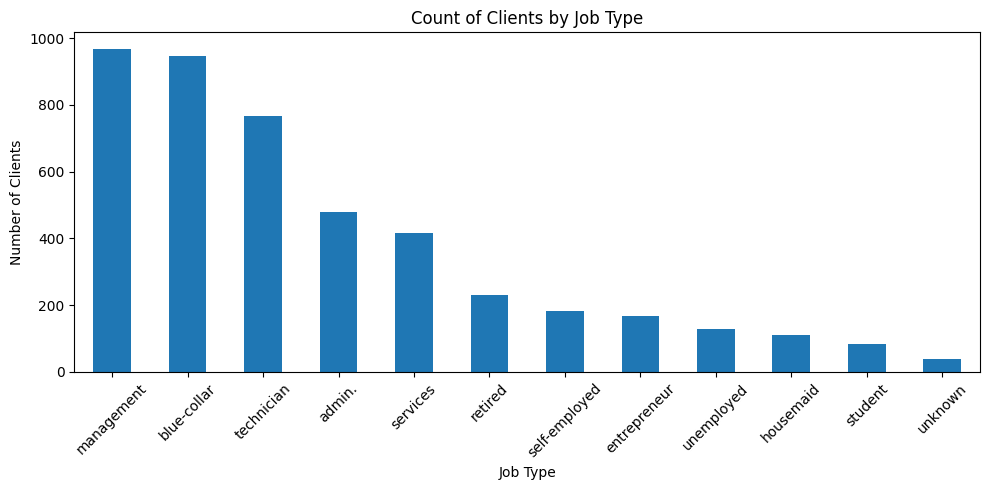

In [16]:
import matplotlib.pyplot as plt

# Count clients by job type
job_counts = pandas_df["job"].value_counts()

# Create bar plot
job_counts.plot(kind="bar", figsize=(10, 5))

plt.title("Count of Clients by Job Type")
plt.xlabel("Job Type")
plt.ylabel("Number of Clients")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**8.	Complex Queries for Insights:**

*	Analyze which month of the year has the highest number of clients contacted, and determine the success rate of the campaign in that month.



In [17]:
from pyspark.sql.functions import col, count, sum, round, when

month_summary = df.groupBy("month").agg(
    count("*").alias("total_contacts"),
    sum(when(col("y") == "yes", 1).otherwise(0)).alias("successful_subscriptions")
).withColumn(
    "success_rate",
    round(col("successful_subscriptions") / col("total_contacts") * 100, 2)
)

month_summary.orderBy(col("total_contacts").desc()).show(1)

+-----+--------------+------------------------+------------+
|month|total_contacts|successful_subscriptions|success_rate|
+-----+--------------+------------------------+------------+
|  may|          1398|                      93|        6.65|
+-----+--------------+------------------------+------------+
only showing top 1 row



*	Find the average duration of contact for clients who subscribed versus those who did not.

In [18]:
from pyspark.sql.functions import avg, round, col

duration_summary = df.groupBy("y").agg(
    round(avg("duration"), 2).alias("average_duration")
)

duration_summary.show()


+---+----------------+
|  y|average_duration|
+---+----------------+
| no|          226.35|
|yes|          552.74|
+---+----------------+



**9.	Correlation Between Age and Balance:**

*	Calculate the correlation coefficient between 'age' and 'balance' to see if there’s any linear relationship between these two variables.


In [19]:
# Calculate correlation between age and balance
correlation = df.stat.corr("age", "balance")

print("Correlation between age and balance:", correlation)

Correlation between age and balance: 0.0838201422447774


**10.	Exploring Loan Defaults:**

*	Analyze the proportion of clients with and without a credit default and visualize the count of defaulters and non-defaulters.


In [20]:
from pyspark.sql.functions import col, count, round

default_summary = df.groupBy("default").agg(
    count("*").alias("client_count")
)

total_clients = df.count()

default_summary = default_summary.withColumn(
    "proportion_percentage",
    round(col("client_count") / total_clients * 100, 2)
)

default_summary.show()

+-------+------------+---------------------+
|default|client_count|proportion_percentage|
+-------+------------+---------------------+
|     no|        4445|                98.32|
|    yes|          76|                 1.68|
+-------+------------+---------------------+



**11.	Contact Method Analysis:**

*	Investigate which contact method ('cellular', 'telephone', etc.) has the highest success rate for term deposit subscriptions.


In [21]:
from pyspark.sql.functions import col, when, avg, round

contact_summary = df.groupBy("contact").agg(
    round(
        avg(when(col("y") == "yes", 1).otherwise(0)) * 100, 2
    ).alias("success_rate")
)

contact_summary.orderBy(
    col("success_rate").desc()
).show()

+---------+------------+
|  contact|success_rate|
+---------+------------+
|telephone|       14.62|
| cellular|       14.36|
|  unknown|        4.61|
+---------+------------+



**12.	Data Processing with Spark SQL:**

*	Calculate the average account balance for different age groups or the most common job types. (Use CREATE TEMPORARY VIEW in Spark SQL to query data using SQL syntax.)


In [24]:
# Create a temporary view
df.createOrReplaceTempView("bank")

# Calculate average account balance by age group
result = spark.sql("""
    SELECT
        CASE
            WHEN age < 30 THEN '<30'
            WHEN age <= 60 THEN '30-60'
            ELSE '>60'
        END AS age_group,
        ROUND(AVG(balance), 2) AS average_balance
    FROM bank
    GROUP BY
        CASE
            WHEN age < 30 THEN '<30'
            WHEN age <= 60 THEN '30-60'
            ELSE '>60'
        END
    ORDER BY age_group
""")

result.show()


# SQL Query: Most common job types
spark.sql("""
    SELECT job, COUNT(*) AS job_count
    FROM bank_data
    GROUP BY job
    ORDER BY job_count DESC
    LIMIT 5
""").show()

+---------+---------------+
|age_group|average_balance|
+---------+---------------+
|    30-60|        1426.88|
|      <30|         1058.1|
|      >60|        2676.35|
+---------+---------------+

+-----------+---------+
|        job|job_count|
+-----------+---------+
| management|      969|
|blue-collar|      946|
| technician|      768|
|     admin.|      478|
|   services|      417|
+-----------+---------+

